In [16]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/shauryajaysthapa/gold-price/gold-24k.csv


In [17]:
file_path="/kaggle/input/datasets/shauryajaysthapa/gold-price/gold-24k.csv"
gold_data=pd.read_csv(file_path)
gold_data.isnull().sum()

published_date    0
price             0
dtype: int64

In [18]:
#sorted dates into acsending order by first converting object data type to data time format
gold_data['published_date']=pd.to_datetime(gold_data['published_date'])
gold_data=gold_data.sort_values('published_date')
gold_data=gold_data.reset_index(drop=True)
gold_data.head()

,published_date,price
0,2010-06-01,35499
1,2010-06-02,36053
2,2010-06-07,35901
3,2010-06-08,36199
4,2010-06-09,36199


In [19]:
gold_data['previous_price']=gold_data['price'].shift(1)
gold_data['price_2_days_ago']=gold_data['price'].shift(2)
gold_data['price_3_days_ago']=gold_data['price'].shift(3)

gold_data=gold_data.dropna()
gold_data.shape

(4665, 5)

In [20]:

from sklearn.model_selection import train_test_split

features=['previous_price','price_2_days_ago',"price_3_days_ago"]

X=gold_data[features]
Y=gold_data['price']

X_train, X_test, Y_train, Y_test= train_test_split(
    X,Y, test_size=0.2, shuffle=False)

print("training rows: ",len(X_train))
print("testing rows:",len(X_test))


training rows:  3732
testing rows: 933


In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
import numpy as np

#creating models
tree_model=DecisionTreeRegressor(random_state=1)
forest_model=RandomForestRegressor(n_estimators=100,random_state=1)

#trainig
tree_model.fit(X_train,Y_train)
forest_model.fit(X_train,Y_train)

#predictions
tree_predictions=tree_model.predict(X_test)
forest_predictions=forest_model.predict(X_test)


In [22]:
for name,predictions in [
    ("Decision Tree", tree_predictions),
    ("Random Forest", forest_predictions)]:

    mae=mean_absolute_error(predictions,Y_test)
    rmse=np.sqrt(mean_squared_error(predictions,Y_test))
    r2=r2_score(Y_test,predictions)
    
    print(f"\n{name}")
    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R²:", round(r2, 4))



Decision Tree
MAE: 91137.51
RMSE: 112962.36
R²: -1.865

Random Forest
MAE: 91080.25
RMSE: 112913.98
R²: -1.8625


In [23]:
print("First date:", gold_data['published_date'].min())
print("Last date:", gold_data['published_date'].max())

print("\nTraining price statistics:")
print(Y_train.describe())

print("\nTesting price statistics:")
print(Y_test.describe())

print("\nFirst 5 actual prices:")
print(Y_test.head())

print("\nFirst 5 predictions:")
print(forest_model.predict(X_test.head()))

First date: 2010-06-08 00:00:00
Last date: 2026-11-09 00:00:00

Training price statistics:
count      3732.000000
mean      67219.889603
std       20593.161314
min       35808.000000
25%       53298.000000
50%       57400.000000
75%       90600.000000
max      117000.000000
Name: price, dtype: float64

Testing price statistics:
count       933.000000
mean     207140.300107
std       66773.682082
min      116000.000000
25%      149700.000000
50%      190600.000000
75%      283200.000000
max      339300.000000
Name: price, dtype: float64

First 5 actual prices:
3735    116500
3736    116300
3737    116900
3738    117400
3739    117700
Name: price, dtype: int64

First 5 predictions:
[116221. 116018. 115982. 116268. 116310.]


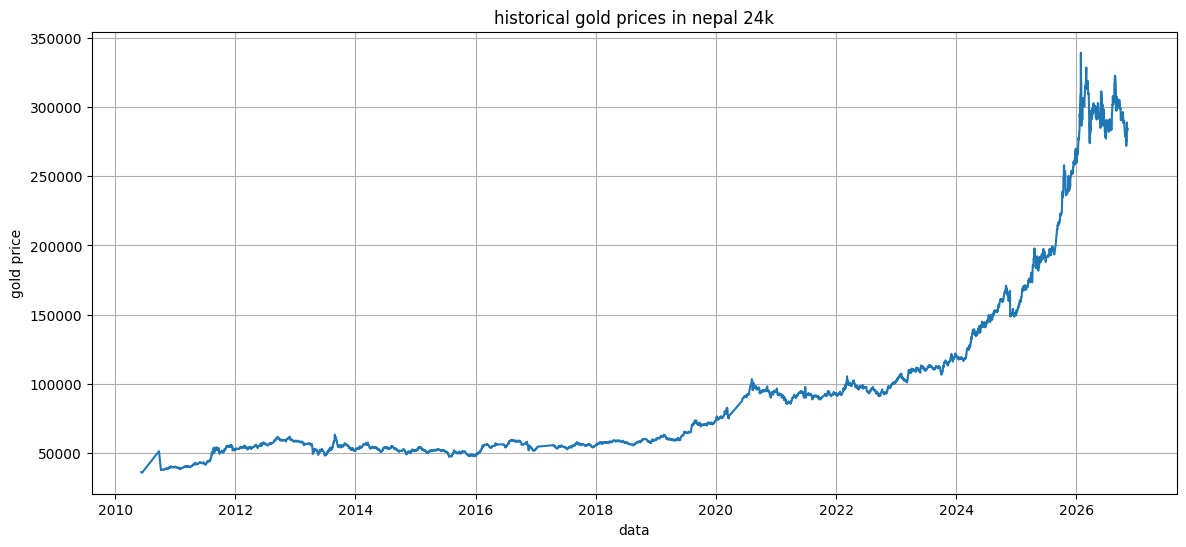

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))
plt.plot(gold_data['published_date'],gold_data['price'])

plt.title("historical gold prices in nepal 24k")
plt.xlabel("data")
plt.ylabel("gold price")

plt.grid()
plt.show()

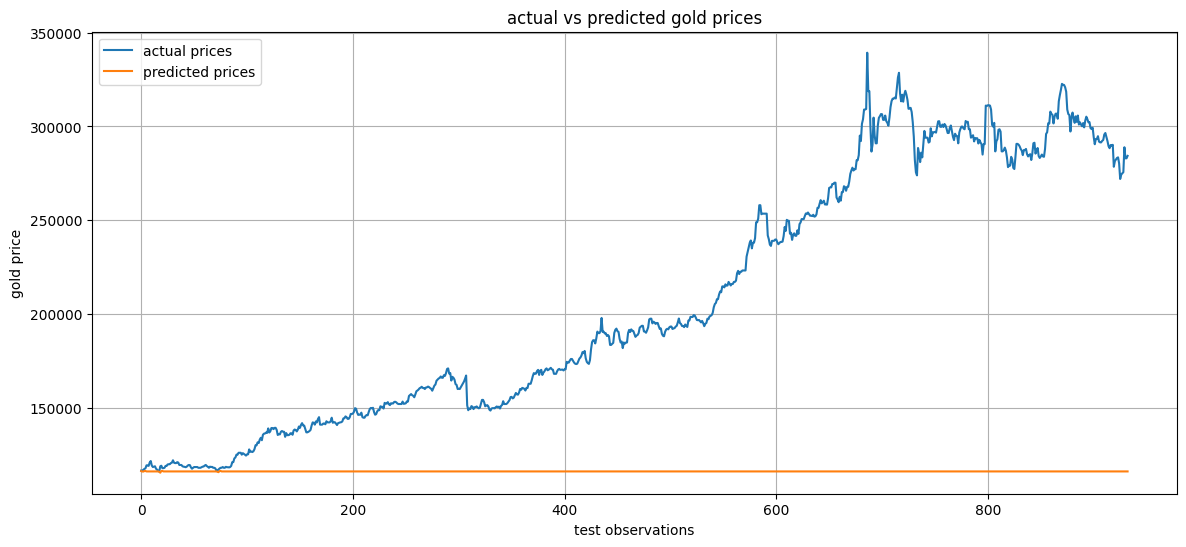

In [25]:
plt.figure(figsize=(14,6))

plt.plot(Y_test.values,label="actual prices")
plt.plot(forest_predictions, label="predicted prices")

plt.title("actual vs predicted gold prices")
plt.xlabel("test observations")
plt.ylabel("gold price")

plt.legend()
plt.grid()
plt.show()

Project Progress Log — Entry 01

Objective: Develop and evaluate machine-learning models to forecast Nepal's 24K gold prices using historical price data.

Dataset:
- Source: Nepal Market Data (GitHub)
- Records initially collected: 4,668
- Features: published_date, price
- Missing values: None
- Period: 13 June 2010 – 9 November 2026
Data preparation:
- Converted dates to datetime format.
- Sorted observations chronologically.
- Removed duplicate dates.
- Created three historical price features.
- Removed the first three observations because of missing lag values.
Initial experiment:
- Training observations: 3,729
- Testing observations: 933
- Models: Decision Tree and Random Forest.
- Result: Both models performed poorly, with negative R² scores.
Key finding:
Tree-based models struggled to extrapolate the substantial increase in gold prices during the testing period.

Next experiment: Linear Regression and comparison against a previous-price baseline.

In [26]:
from sklearn.linear_model import LinearRegression

linear_model=LinearRegression()
linear_model.fit(X_train, Y_train)
linear_predictions=linear_model.predict(X_test)
mae=mean_absolute_error(Y_test, linear_predictions)
rmse=np.sqrt(mean_squared_error(Y_test, linear_predictions))
r2=r2_score(Y_test,linear_predictions)
print("linear regression")
print("mae:", round(mae,2))
print("rmse: ",round(rmse,2))
print("r2: ",round(r2,4))

linear regression
mae: 1706.64
rmse:  3049.65
r2:  0.9979


In [33]:
basline_predictions=X_test["previous_price"]

results={
    "Basline":basline_predictions,
    "Decision Tree": tree_predictions,
    "Random Forest": forest_predictions,
    "Linear Regressions": linear_predictions
}
comparison=[]
for name, predictions in results.items():
    comparison.append({
        "Model":name,
        "MAE": mean_absolute_error(Y_test,predictions),
        "Rmse": np.sqrt(mean_squared_error(Y_test,predictions)),
        "r2": r2_score(Y_test,predictions)
        
    })
results_df=pd.DataFrame(comparison)
results_df.round(4)

,Model,MAE,Rmse,r2
0,Basline,1647.1597,3022.5022,0.9979
1,Decision Tree,91137.5134,112962.3632,-1.8650
2,Random Forest,91080.2454,112913.9814,-1.8625
3,Linear Regressions,1706.6364,3049.6516,0.9979


### Experiment 02: Comparing Regression Models

**Objective:** Evaluate whether alternative regression algorithms can improve gold-price forecasting performance.

**Models tested:**
- Baseline (previous-price prediction)
- Decision Tree Regressor
- Random Forest Regressor
- Linear Regression

**Evaluation metrics:** Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R².

**Results:**

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| Baseline | 1,647.16 | 3,022.50 | 0.9979 |
| Decision Tree | 91,137.51 | 112,962.36 | -1.8650 |
| Random Forest | 91,010.07 | 112,857.52 | -1.8597 |
| Linear Regression | 1,706.61 | 3,049.64 | 0.9979 |

**Findings:**

The baseline model achieved the lowest MAE and RMSE, outperforming all three machine-learning models. Linear Regression produced results close to the baseline, while Decision Tree and Random Forest performed poorly.

**Conclusion:**

The results demonstrate that more complex models do not necessarily produce better predictions. A simple previous-price benchmark is currently the strongest approach. Further experiments are required to determine whether more suitable time-series forecasting techniques can improve performance.

In [37]:
from statsmodels.tsa.arima.model import ARIMA

#reset testing and training indexes
Y_train=Y_train.reset_index(drop=True)
Y_test=Y_test.reset_index(drop=True)

arima_model=ARIMA(Y_train, order=(1,1,1))
arima_fit=arima_model.fit()
arima_predictions=[]
for actual in Y_test:
    prediction= arima_fit.forecast(steps=1)
    arima_predictions.append(float(np.asarray(predictions)[0]))
    arima_fit=arima_fit.append([actual],refit=False)
    

In [44]:
arima_mae=mean_absolute_error(Y_test, arima_predictions)
arima_rmse=np.sqrt(mean_squared_error(Y_test,arima_predictions))
arima_r2=r2_score(Y_test,arima_predictions)
print("ARIMA(1,1,1)")
print("MAE: ",round(arima_mae,2))
print("RMSE: ",round(arima_rmse,2))
print("R2:",round(arima_r2,4))


ARIMA(1,1,1)
MAE:  90670.7
RMSE:  112582.43
R2: -1.8457


In [50]:
results["ARIMA"] = arima_predictions

comparison = []

for name, predictions in results.items():

    comparison.append({
        "Model": name,
        "MAE": mean_absolute_error(Y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(Y_test, predictions)),
        "R2": r2_score(Y_test, predictions)
    })

results_df = pd.DataFrame(comparison)

results_df.sort_values("MAE").round(4)

,Model,MAE,RMSE,R2
0,Basline,1647.1597,3022.5022,0.9979
3,Linear Regressions,1706.6364,3049.6516,0.9979
4,ARIMA,90670.6969,112582.4344,-1.8457
2,Random Forest,91080.2454,112913.9814,-1.8625
1,Decision Tree,91137.5134,112962.3632,-1.8650


### Experiment 03: ARIMA Forecasting

**Objective:** Test a time-series forecasting algorithm specifically designed for sequential data.

**Model:** ARIMA(1,1,1)

**Forecasting approach:** Rolling one-step-ahead predictions, updating the model with each newly observed actual price.

**Results:**

- MAE: 90,670.70
- RMSE: 112,582.43
- R²: -1.8457

**Findings:**

ARIMA performed poorly compared with the baseline and Linear Regression models. Its negative R² indicates that it performed worse than predicting the mean of the testing observations.

**Conclusion:**

The ARIMA(1,1,1) configuration was unable to capture the substantial price movements in the testing period. Further experimentation with time-series methods and model configurations is necessary.

In [62]:
from sklearn.preprocessing import StandardScaler

X_scaler = StandardScaler()
X_train_scaled = X_scaler.fit_transform(X_train)
X_test_scaled = X_scaler.transform(X_test)

Y_scaler = StandardScaler()
Y_train_scaled = Y_scaler.fit_transform(
    Y_train.to_numpy().reshape(-1, 1)
)

In [63]:
#trying with a neural network
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

#model creation
model=keras.Sequential([
    layers.Dense(8,activation='relu',input_shape=(3,)),
    layers.Dense(1)
    
])

model.compile(
    optimizer='adam',
    loss='mean_absolute_error')

historu=model.fit(
    X_train_scaled,
    Y_train_scaled,
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.7618 
Epoch 2/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8978
Epoch 3/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4432
Epoch 4/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1953
Epoch 5/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1278
Epoch 6/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0992
Epoch 7/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0782
Epoch 8/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0637
Epoch 9/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0582
Epoch 10/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0559
Epoch 11/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0531
Epoch 12/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0486
Epoch 13/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0425
Epoch 14/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0345
Epoch 15/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0267

In [64]:
predictions_scaled=model.predict(X_test_scaled)
neural_predictions=Y_scaler.inverse_transform(predictions_scaled).flatten()

30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [66]:
neural_mae=mean_absolute_error(Y_test,neural_predictions)
neural_rmse=np.sqrt(mean_squared_error(Y_test, neural_predictions))
neural_r2=r2_score(Y_test,neural_predictions)
print("Neural network mae:",neural_mae)
print("neural network rmse: ",neural_rmse)
print("neural network r2:",neural_r2)

Neural network mae: 2795.76416015625
neural network rmse:  4609.641417724377
neural network r2: 0.9952292442321777


### Experiment 04: Neural Network

**Model:** Feedforward Neural Network (TensorFlow/Keras)

**Architecture:**
- Input layer: 3 features (previous gold prices)
- Hidden layer: 8 neurons with ReLU activation
- Output layer: 1 neuron (predicted gold price)

**Training configuration:**
- Optimizer: Adam
- Loss function: Mean Absolute Error
- Epochs: 50
- Batch size: 32

**Results:**

| Metric | Result |
|---|---:|
| MAE | 2,795.76 |
| RMSE | 4,609.64 |
| R² | 0.9952 |

**Observations:**

The neural network achieved a high R² score, indicating that it captured much of the variation in gold prices. However, its MAE was higher than both the baseline and linear regression models.

This demonstrates that a more complex model does not necessarily produce more accurate predictions. In this experiment, the simple baseline performed better than the neural network.

**Conclusion:** The neural network was successfully trained, but it did not improve forecasting accuracy over the simpler models.